# Position held: individuals with a dated position, per century

In [1]:
import json
import re
import sys

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only: birth years
POSITIONS_PATH = '../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/position_held_P39_statements.json'  # raw P39 statements
TARGETS_PATH = '../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/targets.json'  # raw labels of the positions
FIRST_CENTURY, LAST_CENTURY = -500, 1900
CENTURY = 100  # years
EXAMPLE_BIRTH_YEARS = (700, 799)  # century of birth of the example individuals
EXAMPLES = 10  # most-linked individuals with a dated position, shown in Figure 3
SPAN_COLORS = {'Before the first position': ORANGE, 'Positions held (first start → last end)': PURPLE, 'After the last position': GREEN}

pl.Config.set_tbl_rows(40)
apply_style()

## Data
Raw Wikidata position held (P39) statements, deprecated ones dropped. A position counts only with both a start time (P580) and an end time (P582); a position without them, or with a point in time (P585) only, does not count. Individuals are placed in their century of birth (`individual_enriched`, Wikidata or estimated).

In [2]:
def year(value):
    sign, digits = re.match(r'([+-]?)(\d+)-', value['time']).groups()
    return -int(digits) if sign == '-' else int(digits)


raw = json.load(open(POSITIONS_PATH))
positions = pl.DataFrame(
    [
        {'qid': qid, 'position_qid': statement['target'],
         'start_year': year(statement['start']) if statement['start'] else None, 'start_precision': statement['start']['precision'] if statement['start'] else None,
         'end_year': year(statement['end']) if statement['end'] else None, 'end_precision': statement['end']['precision'] if statement['end'] else None}
        for qid, statements in raw.items() for statement in statements if statement['rank'] != 'deprecated'
    ],
    schema={'qid': pl.String, 'position_qid': pl.String, 'start_year': pl.Int64, 'start_precision': pl.Int64, 'end_year': pl.Int64, 'end_precision': pl.Int64},
)
del raw
dated = positions.filter(pl.col('start_year').is_not_null() & pl.col('end_year').is_not_null())
print(f"{positions['qid'].n_unique():,} individuals with a position held, {dated['qid'].n_unique():,} with at least one position with a start and an end")
dated.sample(5, seed=42)

979,289 individuals with a position held, 454,417 with at least one position with a start and an end


qid,position_qid,start_year,start_precision,end_year,end_precision
str,str,i64,i64,i64,i64
"""Q65593540""","""Q65482993""",2014,11,2020,11
"""Q21001584""","""Q18171345""",2009,11,2011,11
"""Q98247472""","""Q65477748""",2020,11,2026,11
"""Q6214979""","""Q81531912""",1873,9,1875,9
"""Q65585278""","""Q65192029""",2014,11,2020,11


In [3]:
con = duckdb.connect(DB_PATH, read_only=True)
births = con.sql('''
    SELECT entity.qid AS qid, birth_date.year AS birth_year
    FROM   individual_enriched
    WHERE  birth_date.year IS NOT NULL
''').pl()
con.close()
born_per_century = births.group_by((pl.col('birth_year') // CENTURY * CENTURY).alias('century')).agg(pl.len().alias('individuals born'))
print(f'{births.height:,} individuals with a birth year')

7,641,351 individuals with a birth year


## Preprocessing
### Individuals with a dated position, per century of birth

In [4]:
with_dated_position = pl.DataFrame({'qid': dated['qid'].unique()}).join(births, on='qid', how='left')
print(f"{with_dated_position['birth_year'].null_count():,} of {with_dated_position.height:,} individuals with a dated position have no birth year and are left out")

per_century = (
    with_dated_position.drop_nulls('birth_year')
    .group_by((pl.col('birth_year') // CENTURY * CENTURY).alias('century')).agg(pl.len().alias('with a dated position'))
    .join(born_per_century, on='century', how='right')
    .filter(pl.col('century').is_between(FIRST_CENTURY, LAST_CENTURY))
    .with_columns(pl.col('with a dated position').fill_null(0))
    .with_columns((100 * pl.col('with a dated position') / pl.col('individuals born')).round(2).alias('% of individuals born'))
    .select('century', 'individuals born', 'with a dated position', '% of individuals born')
    .sort('century')
)
assert per_century['century'].is_unique().all()
per_century

53,878 of 454,417 individuals with a dated position have no birth year and are left out


century,individuals born,with a dated position,% of individuals born
i64,u32,u32,f64
-500,443,72,16.25
-400,596,104,17.45
-300,702,236,33.62
-200,701,234,33.38
-100,949,166,17.49
0,928,142,15.3
100,1316,96,7.29
200,1718,138,8.03
300,1810,226,12.49


### Example individuals
The most-linked individuals (Wikipedia pages) born in the century with a dated position: birth, start of their first position, end of their last position, death, and the peak currently in the database (first and last work, notebook 02).

In [5]:
position_spans = dated.group_by('qid').agg(
    pl.col('start_year').min().alias('first_position'),
    pl.col('position_qid').sort_by('start_year').first().alias('first_position_qid'),
    pl.col('end_year').max().alias('last_position'),
    pl.col('position_qid').sort_by('end_year').last().alias('last_position_qid'),
    pl.len().alias('positions'),
)
con = duckdb.connect(DB_PATH, read_only=True)
con.register('position_spans', position_spans.to_arrow())
examples = con.sql('''
    SELECT individual_enriched.entity.qid AS qid,
           individual_enriched.entity.label_en AS name,
           len(individual.sitelink) AS sitelinks,
           individual_enriched.birth_date.year AS birth_year,
           individual_enriched.birth_date.source AS birth_source,
           position_spans.first_position,
           position_spans.first_position_qid,
           position_spans.last_position,
           position_spans.last_position_qid,
           position_spans.positions,
           individual_enriched.death_date.year AS death_year,
           individual_enriched.death_date.source AS death_source,
           individual_enriched.first_work_date.year AS peak_start,
           individual_enriched.last_work_date.year AS peak_end
    FROM   individual_enriched
    JOIN   individual ON individual.entity.qid = individual_enriched.entity.qid
    JOIN   position_spans ON position_spans.qid = individual_enriched.entity.qid
    WHERE  individual_enriched.birth_date.year BETWEEN $first AND $last
           AND individual_enriched.death_date.year IS NOT NULL AND individual_enriched.entity.label_en IS NOT NULL
    ORDER BY sitelinks DESC, qid
    LIMIT  $examples
''', params={'first': EXAMPLE_BIRTH_YEARS[0], 'last': EXAMPLE_BIRTH_YEARS[1], 'examples': EXAMPLES}).pl().sort('birth_year', descending=True)
con.close()
targets = json.load(open(TARGETS_PATH))
position_label = {qid: (targets.get(qid) or {}).get('label_en') or qid for qid in [*examples['first_position_qid'], *examples['last_position_qid']]}
del targets
examples = examples.with_columns(
    pl.col('first_position_qid').replace_strict(position_label).alias('first_position_name'),
    pl.col('last_position_qid').replace_strict(position_label).alias('last_position_name'),
)
assert examples.height == EXAMPLES
examples.select('name', 'birth_year', 'first_position', 'first_position_name', 'last_position', 'last_position_name', 'death_year', 'positions')

name,birth_year,first_position,first_position_name,last_position,last_position_name,death_year,positions
str,i64,i64,str,i64,str,i64,u32
"""Gregory IV""",795,827,"""Pope""",844,"""Pope""",844,1
"""Adrian II""",792,867,"""Pope""",872,"""Pope""",872,1
"""Leo IV""",790,847,"""Pope""",855,"""Pope""",855,1
"""Louis the Pious""",778,814,"""Carolingian Roman emperor""",840,"""king of Franks""",840,2
"""Harun al-Rashid""",766,786,"""Abbasid caliph""",809,"""Abbasid caliph""",809,1
"""Leo III""",750,796,"""Pope""",816,"""Pope""",816,1
"""Charlemagne""",748,768,"""king of Franks""",814,"""king of Franks""",814,2
"""Pepin the Short""",715,741,"""Mayor of the Palace""",768,"""king of Franks""",768,2
"""Adrian I""",700,772,"""Pope""",795,"""Pope""",795,1


## Figures
### Figure 1: Individuals with a dated position held, per century of birth

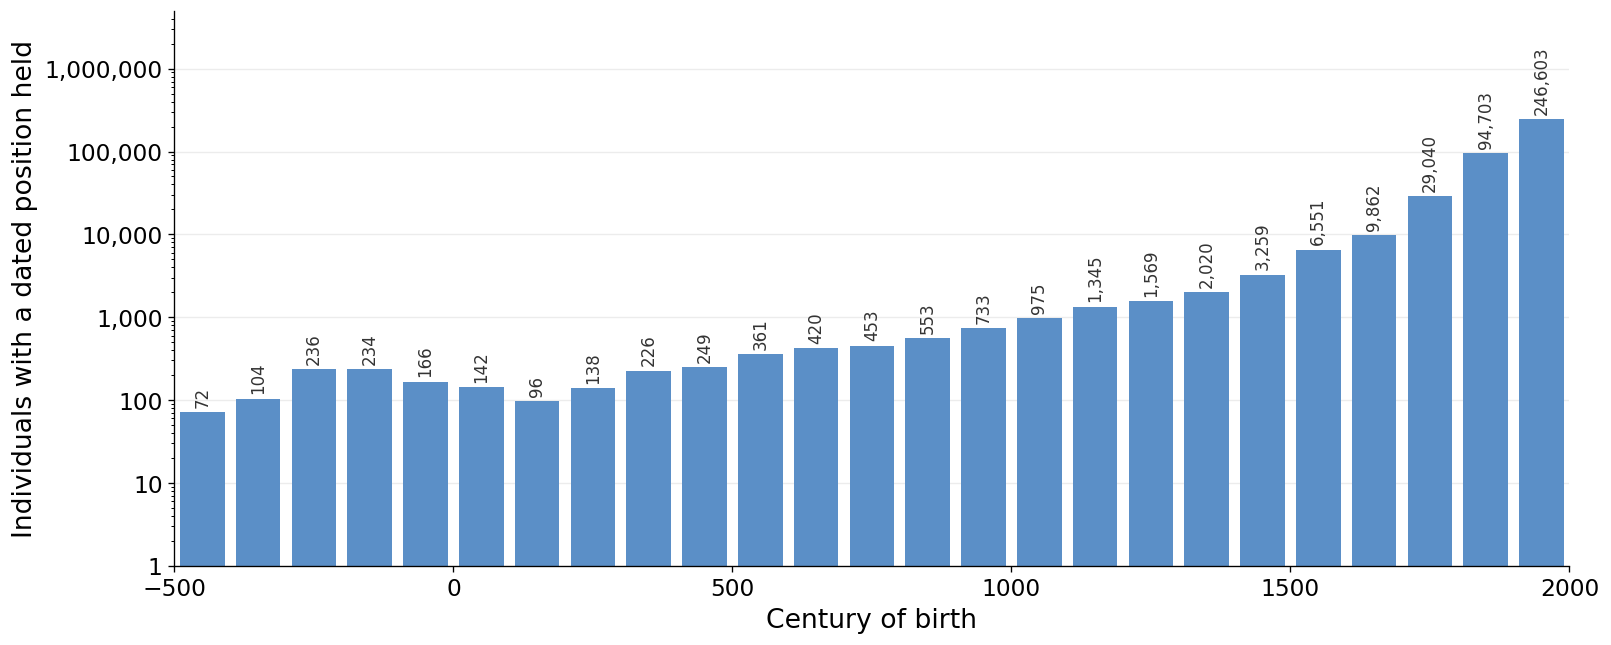

In [6]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.bar(per_century['century'] + CENTURY / 2, per_century['with a dated position'], width=CENTURY * 0.8, color=MAIN_COLOR)
for century, n in per_century.select('century', 'with a dated position').iter_rows():
    ax.text(century + CENTURY / 2, n * 1.15, f'{n:,}', ha='center', va='bottom', fontsize=VALUE_LABEL_FONTSIZE - 2, rotation=90, color=TEXT)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_ylim(1, per_century['with a dated position'].max() * 20)
ax.set_xlim(FIRST_CENTURY, LAST_CENTURY + CENTURY)
ax.set_xlabel('Century of birth')
ax.set_ylabel('Individuals with a dated position held')
ax.grid(axis='y')
plt.show()

### Figure 2: Share of the individuals born in each century with a dated position held

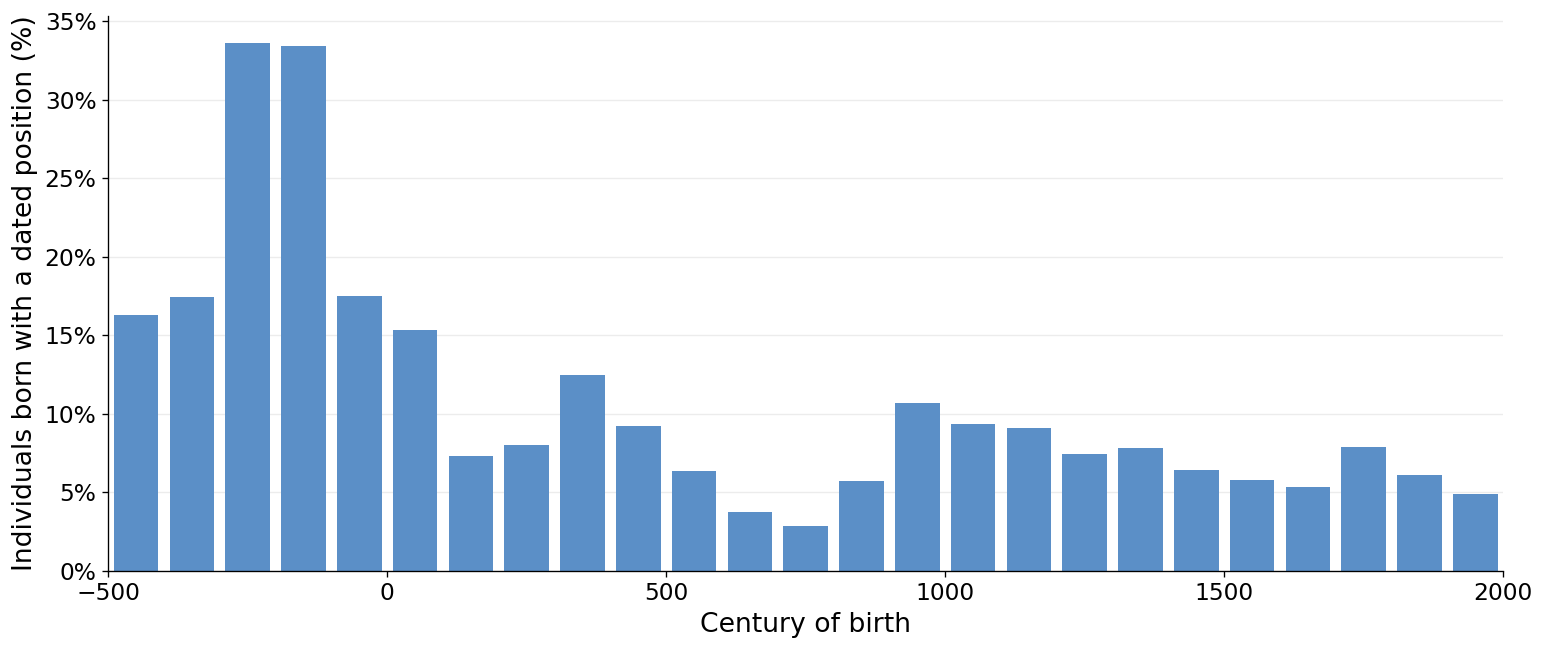

In [7]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.bar(per_century['century'] + CENTURY / 2, per_century['% of individuals born'], width=CENTURY * 0.8, color=MAIN_COLOR)
ax.set_xlim(FIRST_CENTURY, LAST_CENTURY + CENTURY)
ax.yaxis.set_major_formatter(PERCENT)
ax.set_xlabel('Century of birth')
ax.set_ylabel('Individuals born with a dated position (%)')
ax.grid(axis='y')
plt.show()

### Figure 3: Birth, positions held and death of the most-linked individuals born 700–799

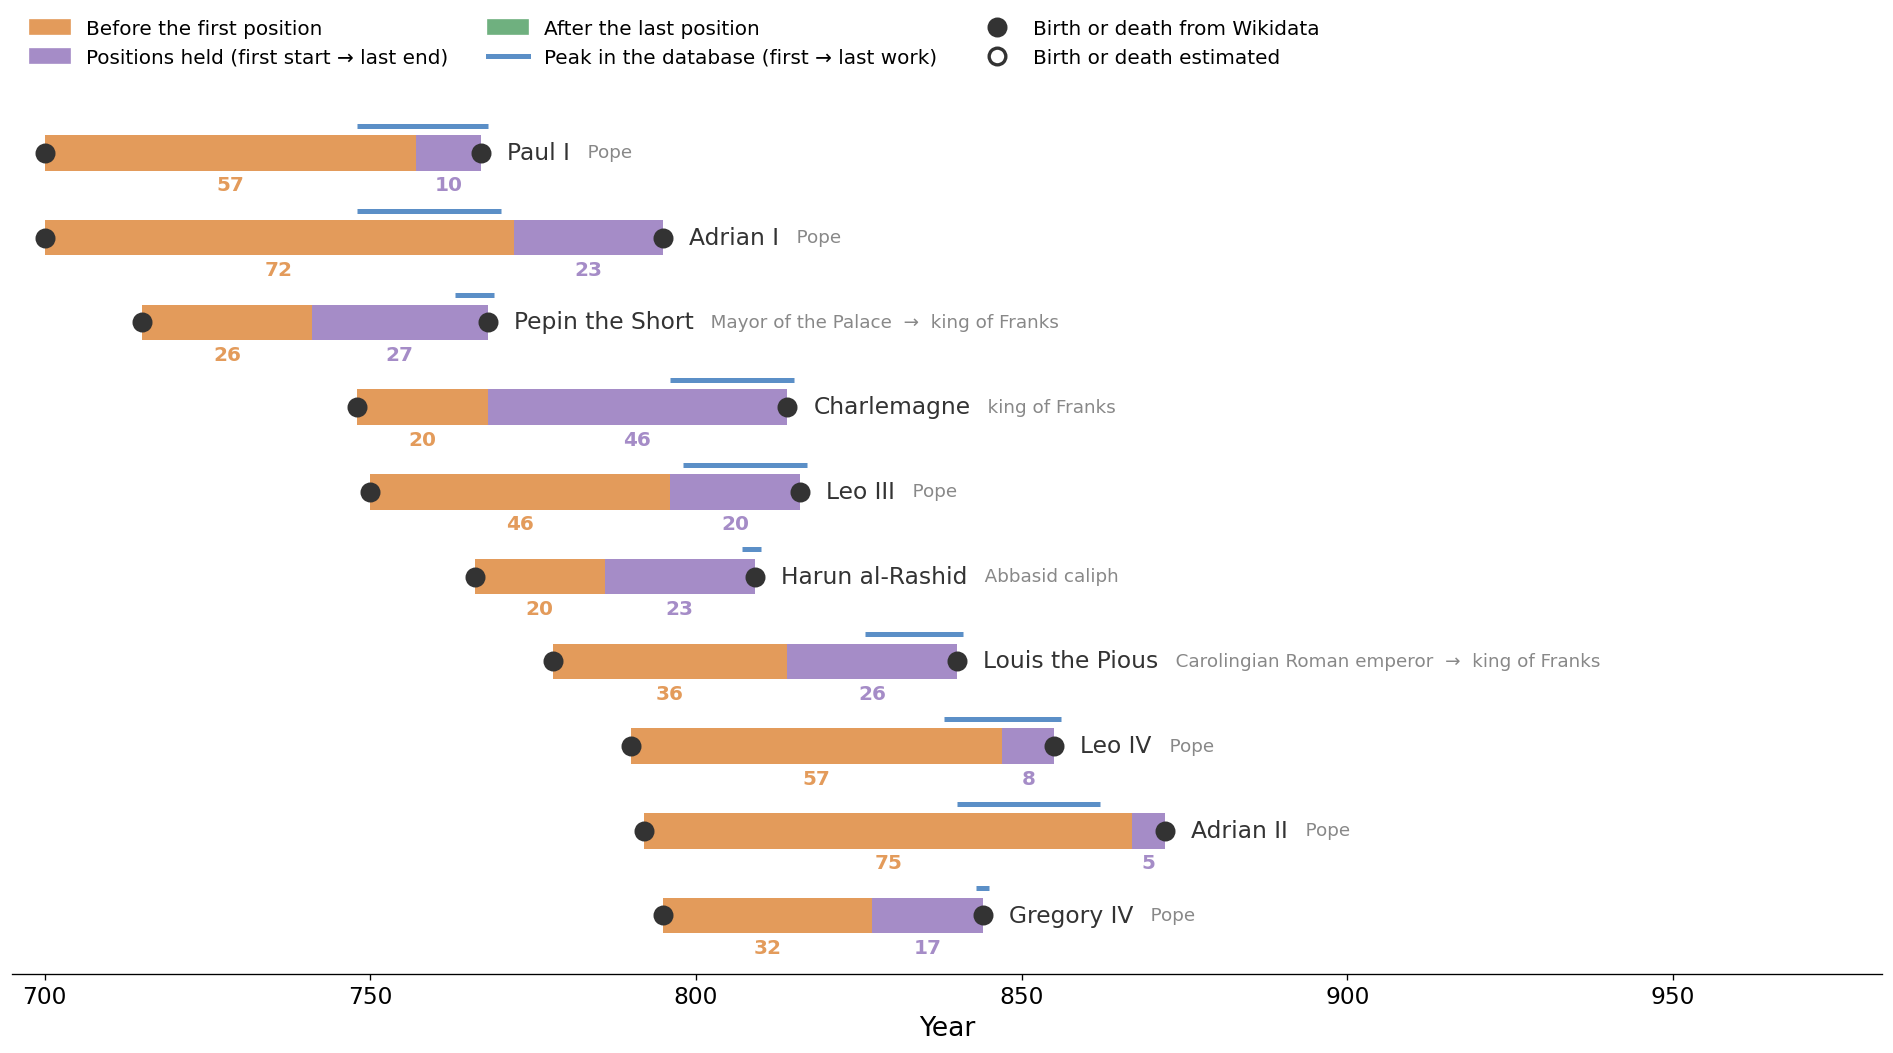

In [8]:
fig, ax = plt.subplots(figsize=(16, 9))
for row, person in enumerate(examples.iter_rows(named=True)):
    spans = [(person['birth_year'], person['first_position']), (person['first_position'], person['last_position']), (person['last_position'], person['death_year'])]
    for (label, color), (start, end) in zip(SPAN_COLORS.items(), spans):
        if end > start:
            ax.barh(row, end - start, left=start, height=0.42, color=color)
            ax.text((start + end) / 2, row - 0.27, end - start, ha='center', va='top', fontsize=12, color=color, fontweight='bold')
    ax.plot([person['peak_start'], person['peak_end'] + 1], [row + 0.32, row + 0.32], color=BLUE, linewidth=3, solid_capstyle='butt')
    for year, source in [(person['birth_year'], person['birth_source']), (person['death_year'], person['death_source'])]:
        ax.plot(year, row, 'o', markersize=10, markeredgewidth=2, color=TEXT, markerfacecolor='white' if source == 'estimated' else TEXT, zorder=3)
    name = ax.text(max(person['death_year'], person['last_position']) + 4, row, person['name'], va='center', fontsize=14, color=TEXT)
    positions = person['first_position_name'] if person['first_position_qid'] == person['last_position_qid'] else f"{person['first_position_name']}  →  {person['last_position_name']}"
    ax.annotate(f'   {positions}', xycoords=name, xy=(1, 0.5), va='center', fontsize=11, color=MUTED_TEXT)
ax.legend(handles=[
    *[Patch(color=color, label=label) for label, color in SPAN_COLORS.items()],
    Line2D([], [], color=BLUE, linewidth=3, label='Peak in the database (first → last work)'),
    Line2D([], [], marker='o', linestyle='', markersize=10, markeredgewidth=2, color=TEXT, label='Birth or death from Wikidata'),
    Line2D([], [], marker='o', linestyle='', markersize=10, markeredgewidth=2, color=TEXT, markerfacecolor='white', label='Birth or death estimated'),
], loc='lower left', bbox_to_anchor=(0, 1), ncol=3, fontsize=12)
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_xlim(examples['birth_year'].min() - 5, examples['death_year'].max() + 110)
ax.set_xlabel('Year')
plt.tight_layout()
plt.show()